# Git, GitHub i analiza danych w Pythonie: pierwsze kroki
Gabriela Słomiany · Warsztaty dla początkujących

## Część 1 · Git i GitHub
Uruchamiamy Gita z poziomu notebooka (`!`). Tworzymy małe lokalne repozytorium, więc wszystkie polecenia działają bez GitHuba.

`!git --version`><br>
`!mkdir -p demo-repo`<br>
`%cd demo-repo`<br>
`!git init`<br>
`!git config user.name "Student"`<br>
`!git config user.email "student@example.com"`<br>
`!git status`              # sprawdź, co się zmieniło<br>
`!git add .`               # dodaj wszystkie zmiany do stage<br>
`!git commit -m "Pierwszy commit"`   # zapisz commit projektu<br>
`!git log --oneline`       # historia projektu<br>
`!git branch new-feature`  # utwórz nową gałąź<br>
`!git branch`              # wyświetl gałęzie<br>

### Te polecenia wymagają repozytorium na GitHubie:<br>
`!git clone` <url>   `!git push`   `!git pull`<br><br>

`cd`<br>
`pwd`<br>
`ls`<br>
`mv`<br>
`rm`<br>
`-d`<br>


## Część 2 · Analiza danych w Pythonie
### Importy i przykładowe dane

In [14]:
import pandas as pd              # tabele (DataFrame)
import numpy as np               # szybkie tablice liczbowe
import matplotlib.pyplot as plt  # podstawowe wykresy
import seaborn as sns            # ładniejsze wykresy statystyczne

# Tworzymy przykładowy plik data.csv, żeby reszta notebooka działała
rng = np.random.default_rng(42)
n = 100
sample = pd.DataFrame({
    'age': rng.integers(20, 61, n),
    'city': rng.choice(['Wrocław', 'Kraków', 'Warszawa'], n),
})
sample['salary'] = (3000 + sample['age'] * 120
                    + sample['city'].map({'Wrocław': 800, 'Kraków': 600, 'Warszawa': 1500})
                    + rng.normal(0, 800, n)).round(0)
sample.loc[rng.choice(n, 5, replace=False), 'age'] = np.nan  # kilka brakujących wartości
sample.to_csv('data.csv', index=False)

print(sample.shape)
sample.head()

(100, 3)


,age,city,salary
0,23.0,Warszawa,7580.0
1,51.0,Wrocław,9196.0
2,46.0,Warszawa,9717.0
3,37.0,Wrocław,9279.0
4,37.0,Warszawa,8655.0


### NumPy liczy na całej liście naraz

In [15]:
arr = np.array([1, 2, 3, 4])  # utwórz tablicę
print(arr.mean())             # średnia wartości
print(arr * 2)                # pomnóż każdy element

2.5
[2 4 6 8]


### pandas wczytuje plik CSV do tabeli

In [16]:
df = pd.read_csv('data.csv')  # wczytaj plik do DataFrame
print(df.shape)               # (wiersze, kolumny)
df.head()                     # pokaż pierwsze 5 wierszy

(100, 3)


,age,city,salary
0,23.0,Warszawa,7580.0
1,51.0,Wrocław,9196.0
2,46.0,Warszawa,9717.0
3,37.0,Wrocław,9279.0
4,37.0,Warszawa,8655.0


### Trzy polecenia pokazują, co jest w danych

In [17]:
df.info()                     # typy kolumn i brakujące wartości
display(df.describe())        # statystyki opisowe
df.isna().sum()               # liczba braków w każdej kolumnie

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     95 non-null     float64
 1   city    100 non-null    str    
 2   salary  100 non-null    float64
dtypes: float64(2), str(1)
memory usage: 2.5 KB


,age,salary
count,95.000000,100.000000
mean,40.757895,8849.180000
std,11.327537,1630.643712
min,21.000000,5434.000000
25%,31.500000,7563.000000
50%,40.000000,8788.000000
75%,51.000000,9923.250000
max,60.000000,12251.000000


age       5
city      0
salary    0
dtype: int64

### Nawiasy kwadratowe wybierają kolumny i filtrują wiersze

In [18]:
display(df['age'].head())                  # jedna kolumna
display(df[df['age'] > 30].head())         # wiersze, gdzie wiek > 30
df.groupby('city')['salary'].mean()        # średnie wynagrodzenie w każdym mieście

0    23.0
1    51.0
2    46.0
3    37.0
4    37.0
Name: age, dtype: float64

,age,city,salary
1,51.0,Wrocław,9196.0
2,46.0,Warszawa,9717.0
3,37.0,Wrocław,9279.0
4,37.0,Warszawa,8655.0
5,55.0,Warszawa,11690.0


city
Kraków      8522.897436
Warszawa    9422.800000
Wrocław     8704.548387
Name: salary, dtype: float64

### Matplotlib rysuje wykres w trzech linijkach

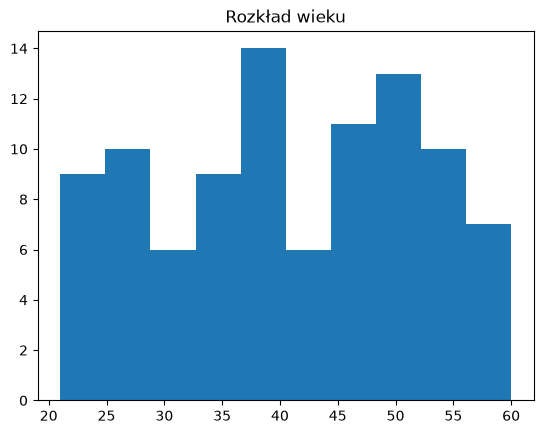

In [19]:
plt.hist(df['age'].dropna(), bins=10)  # histogram wieku
plt.title('Rozkład wieku')             # dodaj tytuł
plt.show()                             # wyświetl wykres

### seaborn tworzy wykresy statystyczne w jednej linijce

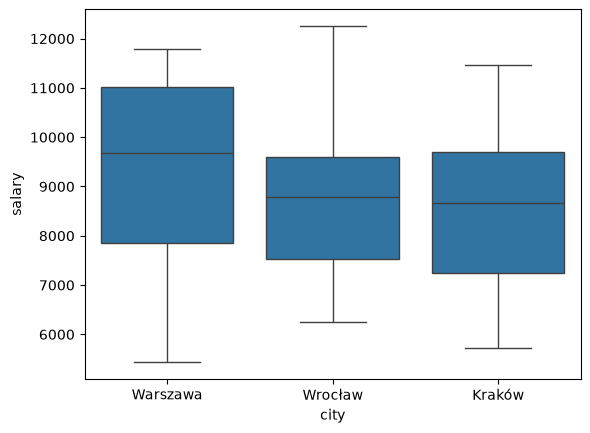

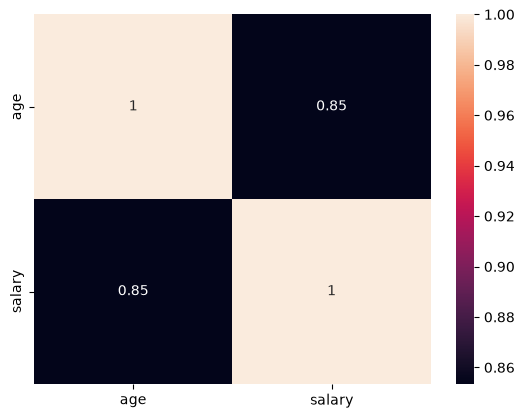

In [20]:
sns.boxplot(data=df, x='city', y='salary')           # rozrzut wynagrodzeń w miastach
plt.show()
sns.heatmap(df.corr(numeric_only=True), annot=True)  # korelacje
plt.show()

## Część 3 · Pierwszy kontakt z uczeniem maszynowym
### scikit-learn trenuje model w trzech krokach

In [21]:
from sklearn.linear_model import LinearRegression     # wybierz typ modelu
from sklearn.model_selection import train_test_split

data = df.dropna()
X = data[['age']]
y = data['salary']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()          # utwórz model
model.fit(X_train, y_train)         # ucz się na danych
model.predict(X_test)[:5]           # zrób predykcje

array([ 8412.96762014, 10766.87684221,  7793.51782485,  7297.95798863,
        6554.61823429])

In [26]:
print(model.coef_.round(2), model.intercept_.round(2))         # współczynniki regresji
print(model.score(X_test, y_test))             # R^2 na danych testowych


[123.89] 3705.15
0.6710165037581779


Text(0.5, 1.0, 'Regresja liniowa: wiek vs wynagrodzenie')

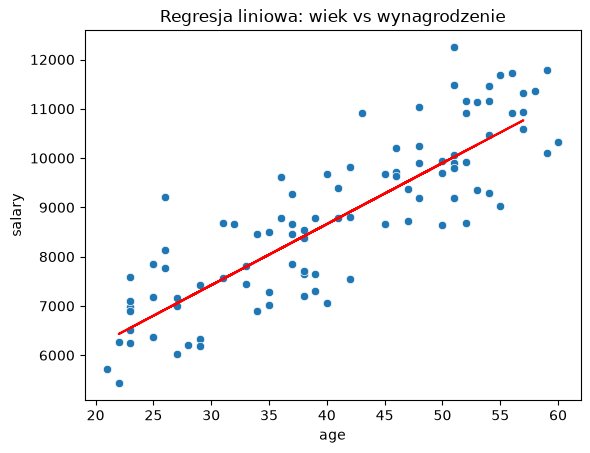

In [27]:
sns.scatterplot(data=data, x='age', y='salary')  # punkty danych
plt.plot(X_test, model.predict(X_test), color='red')  # linia regresji
plt.title('Regresja liniowa: wiek vs wynagrodzenie')